# One test set, two questions: does the model clear the bar, and is B better than A

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/firefly1248/demo-notebooks/blob/main/notebooks/model_comparison/model_comparison_proportion_bounds.ipynb)

A model is scored on one labelled test set, and the score is a share: precision, accuracy, recall.
Two questions follow. Is the true share above a threshold the business set? And is model B better
than model A on the same rows? Both are answered by an interval around a share, and both go wrong
in small, specific ways: the interval formula, the confidence level a library call actually returns,
and whether the two models' scores are treated as paired.

Napkin examples only, no data and no models: every number is a count. Seconds on any CPU.

**Convention.** A one-sided 95% lower bound is the lower end of a two-sided 90% interval.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import scipy, statsmodels
from scipy.stats import norm, binom, binomtest
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

print("scipy", scipy.__version__, "statsmodels", statsmodels.__version__)

Z95 = norm.ppf(0.95)  # one-sided 95%
THRESHOLD = 0.90

def wald_lower(k, n, z):
    p = k / n
    return p - z * np.sqrt(p * (1 - p) / n)

def wilson_lower(k, n, z):
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half

BOUNDS = {"Wald": wald_lower, "Wilson": wilson_lower}

scipy 1.18.1 statsmodels 0.14.6


## The library trap

`wilson_lower` should match the libraries. It does, at the right argument: scipy takes the
two-sided confidence level, statsmodels takes `alpha` for a two-sided interval. So
`proportion_confint(k, n, alpha=0.05)` is a two-sided 95% interval, and its lower end is a one-sided
97.5% bound.

In [2]:
k, n = 29, 30
for label, low in (
    (f"own Wilson, z = {Z95:.3f}", wilson_lower(k, n, Z95)),
    ("scipy, confidence_level=0.90", binomtest(k, n).proportion_ci(confidence_level=0.90, method="wilson").low),
    ("statsmodels, alpha=0.10", proportion_confint(k, n, alpha=0.10, method="wilson")[0]),
    ("statsmodels, alpha=0.05 (97.5%)", proportion_confint(k, n, alpha=0.05, method="wilson")[0]),
):
    print(f"{label:<32} {low:.4f}")

own Wilson, z = 1.645            0.8636
scipy, confidence_level=0.90     0.8636
statsmodels, alpha=0.10          0.8636
statsmodels, alpha=0.05 (97.5%)  0.8333


## Does 29 of 30 clear 0.90?

The observed share is above the threshold. The question is whether the lower bound is. Wald is the
textbook interval, `p ± z sqrt(p (1 - p) / n)`; Wilson inverts the score test instead and keeps its
interval inside [0, 1].

In [3]:
for k in (29, 30):
    for name, bound in BOUNDS.items():
        low = bound(k, 30, Z95)
        print(f"{k} of 30, {name:>6} lower bound {low:.3f} -> {'clears' if low >= THRESHOLD else 'does not clear'} {THRESHOLD}")

29 of 30,   Wald lower bound 0.913 -> clears 0.9
29 of 30, Wilson lower bound 0.864 -> does not clear 0.9
30 of 30,   Wald lower bound 1.000 -> clears 0.9
30 of 30, Wilson lower bound 0.917 -> clears 0.9


At 29 of 30 the two formulas give opposite answers. At 30 of 30 `p (1 - p)` is zero, so Wald's
interval has zero width and its lower bound is the observed share itself.

## How often the bound lies above the truth

A one-sided 95% lower bound should land above the true share at most 5% of the time. With counts
this can be computed exactly: sum the binomial probabilities of every `k` whose bound exceeds the
true `p`. At `n = 30` and a true share of 0.95 only `k = 30` puts Wald's bound above the truth, so
its miss rate is just the probability of a perfect score.

In [4]:
def miss_rate(bound, n, p, z=Z95):
    k = np.arange(n + 1)
    return binom.pmf(k, n, p)[bound(k, n, z) > p].sum()

n, p = 30, 0.95
print(f"P({n} of {n} | p = {p}) = {p ** n:.3f}")
for name, bound in BOUNDS.items():
    print(f"{name:>6} misses {miss_rate(bound, n, p):.1%} (nominal 5%)")

P(30 of 30 | p = 0.95) = 0.215
  Wald misses 21.5% (nominal 5%)
Wilson misses 0.0% (nominal 5%)


Across true shares at `n = 30`, Wald's miss rate climbs as the share approaches one, because the
perfect and near-perfect scores that become likely there are exactly the ones its interval is too
narrow for. Wilson's saw-tooths around the nominal level, from the discreteness of the counts, and
drops to zero near the top: there it errs on the cautious side.

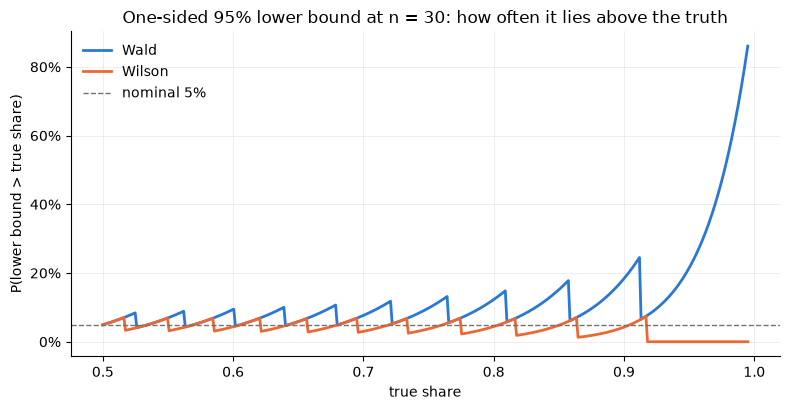

In [5]:
ps = np.linspace(0.5, 0.995, 400)
fig, ax = plt.subplots(figsize=(8, 4.2))
for (name, bound), color in zip(BOUNDS.items(), ("#2a78d6", "#eb6834")):
    ax.plot(ps, [miss_rate(bound, n, p) for p in ps], color=color, lw=2, label=name)
ax.axhline(0.05, color="#73726c", lw=1, ls="--", label="nominal 5%")
ax.set(xlabel="true share", ylabel="P(lower bound > true share)",
       title=f"One-sided 95% lower bound at n = {n}: how often it lies above the truth")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(frameon=False, loc="upper left")
ax.grid(alpha=0.25, lw=0.6)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig("model_comparison_proportion_bounds.png", dpi=150, facecolor="white")
plt.show()

## What a pass costs

From here on the bound is Wilson's. A threshold of 0.90 on the lower bound is a stricter bar than
0.90 on the observed share, by how much depends on the test-set size and the confidence level. The
smallest passing count, as a share of `n`:

In [6]:
def needed(n, z, strict=False):
    k = np.arange(n + 1)
    bound = wilson_lower(k, n, z)
    return k[bound > THRESHOLD + 1e-12 if strict else bound >= THRESHOLD - 1e-12][0]

LEVELS = ((Z95, f"z = {Z95:.3f}, {norm.cdf(Z95):.0%}"), (1.0, f"z = 1, {norm.cdf(1):.0%}"))
for z, name in LEVELS:
    print(f"{name:<18}", {n: round(float(needed(n, z) / n), 3) for n in (100, 200, 1000)})

z = 1.645, 95%     {100: 0.95, 200: 0.935, 1000: 0.916}
z = 1, 84%         {100: 0.93, 200: 0.925, 1000: 0.91}


The bar falls towards 0.90 as the test set grows, and a lower confidence level lowers it too. The
other side of the same rule: a model whose true share is exactly 0.90 should pass about as rarely as
the confidence level allows. At `n = 100` and `n = 200`, with the bound required to reach the
threshold and, in brackets, to exceed it:

In [7]:
for n in (100, 200):
    for z, name in LEVELS:
        k, k_strict = needed(n, z), needed(n, z, strict=True)
        print(f"{name:<18} needs {k} of {n} (bound {wilson_lower(k, n, z):.4f}), passes {binom.sf(k - 1, n, THRESHOLD):.1%}"
              f" ({k_strict}: {binom.sf(k_strict - 1, n, THRESHOLD):.1%}), nominal {norm.sf(z):.1%}")

z = 1.645, 95%     needs 95 of 100 (bound 0.9008), passes 5.8% (95: 5.8%), nominal 5.0%
z = 1, 84%         needs 93 of 100 (bound 0.9000), passes 20.6% (94: 11.7%), nominal 15.9%
z = 1.645, 95%     needs 187 of 200 (bound 0.9001), passes 5.7% (187: 5.7%), nominal 5.0%
z = 1, 84%         needs 185 of 200 (bound 0.9042), passes 14.3% (185: 14.3%), nominal 15.9%


At `n = 100` and `z = 1` the needed count puts the bound exactly on the threshold, because the score statistic
`(k/n - 0.90) / sqrt(0.9 * 0.1 / n)` comes out at exactly 1. Whether that tie passes moves the pass
rate from above nominal to below it: the discreteness of the counts can push either way. On both
sides of the tie, `z = 1` passes a model that is only at the threshold far more often than one-sided
95% does.

## Is B better than A on the same 1000 rows?

A is wrong on 150 rows. B fixes 50 of them and breaks 30 rows that A gets right. On the same rows
the comparison is paired, and only the rows where the two models disagree carry information about
the difference. The rows both get right or both get wrong cancel.

An unpaired two-proportion test treats the two scores as independent samples. The models agree on
most rows, so the variance of the difference is much smaller than independence implies, and the
unpaired test overstates it. McNemar's test uses the disagreements only.

In [8]:
# the 2 x 2 table: both right, A right only (B breaks), B right only (B fixes), both wrong
both_right, breaks, fixes, both_wrong = 820, 30, 50, 100
n = both_right + breaks + fixes + both_wrong
correct_a, correct_b = both_right + breaks, both_right + fixes
print(f"A {correct_a / n:.1%}, B {correct_b / n:.1%}")
print(f"unpaired two-proportion p = {proportions_ztest([correct_b, correct_a], [n, n])[1]:.3f}")
print(f"McNemar exact p           = {binomtest(breaks, fixes + breaks, 0.5).pvalue:.3f}")  # binomial test on the disagreements

A 85.0%, B 87.0%
unpaired two-proportion p = 0.197
McNemar exact p           = 0.033


Pairing turns an unremarkable difference into a significant one. Significance is still not the
decision. Fix a margin first and read the paired 90% interval of `B - A` against it: entirely above
the margin is better, entirely below minus the margin is worse, entirely inside it is equivalent,
and an interval that crosses an edge is unclear. Higher is better for accuracy, so the direction of
the verdict is fixed with the margin.

The interval uses the normal approximation to the paired difference. A bootstrap over rows, drawn
from the four cells of the table, has the same variance by construction, so it checks only that the
normal shape holds at these counts, not the standard error.

In [9]:
diff = (fixes - breaks) / n
se = np.sqrt(fixes + breaks - (fixes - breaks) ** 2 / n) / n
low, high = diff - Z95 * se, diff + Z95 * se
print(f"B - A = {diff:.3f}, 90% interval [{low:.4f}, {high:.4f}]")

cells = np.array([both_right, breaks, fixes, both_wrong]) / n
draws = np.random.default_rng(0).multinomial(n, cells, size=20000)
print("bootstrap over rows [{:.4f}, {:.4f}]".format(*np.percentile((draws[:, 2] - draws[:, 1]) / n, [5, 95])))

MARGIN = 0.01  # one accuracy point, set before the run
verdict = ("better" if low > MARGIN else "worse" if high < -MARGIN else
           "equivalent" if -MARGIN < low and high < MARGIN else "unclear")
print(f"margin {MARGIN} -> {verdict}")

B - A = 0.020, 90% interval [0.0053, 0.0347]


bootstrap over rows [0.0050, 0.0350]
margin 0.01 -> unclear


## Takeaways

- A lower bound is the right reading of "above the threshold", and on small test sets the formula
  decides the answer. Wald's bound has zero width at a perfect score and lies above the truth far
  more often than its nominal level near one; Wilson's stays near nominal and turns cautious at
  the top.
- Check what confidence level a library call returns: one-sided 95% is `alpha=0.10` in
  `proportion_confint`.
- A bar on the lower bound is stricter than the same bar on the observed share, more so on a small
  test set. Lowering the confidence level to reach it raises the chance of passing a model that is
  only at the threshold.
- Two models on the same rows are paired. An unpaired test overstates the variance of the
  difference; McNemar uses the disagreements only. A significant difference can still be unclear
  against a margin set in advance.